# Milestone 3 - Task 6: Model Performance Comparison

## 1. Objective

The objective of this task is to compare Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and XGBoost using the same held-out test dataset.

The models will be evaluated using accuracy, precision, recall, F1 score, ROC-AUC, and confusion matrices. These metrics help identify which model best predicts Kickstarter campaign success while accounting for the consequences of incorrect predictions.

## 2. Load and Consolidate Results

The metrics from the previous modeling tasks are consolidated into one comparison table. The selected tuned models are used where applicable. KNN's ROC-AUC will be calculated from predicted probabilities using the same stratified train/test split.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


df = pd.read_csv("../data/kickstarter_us_filtered.csv")


df["success"] = (df["status"] == "successful").astype(int)

df["state"] = (
    df["location"]
    .str.rsplit(",", n=1)
    .str[-1]
    .str.strip()
)

numerical_features = ["goal", "duration", "levels"]
categorical_features = ["category", "subcategory", "state"]
selected_features = numerical_features + categorical_features

X = df[selected_features].copy()
y = df["success"].copy()


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Refit KNN with the selected K value
knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=41))
    ]
)

knn_model.fit(X_train, y_train)

# Predict labels and success probabilities
knn_predictions = knn_model.predict(X_test)
knn_probabilities = knn_model.predict_proba(X_test)[:, 1]


knn_metrics = {
    "Accuracy": accuracy_score(y_test, knn_predictions),
    "Precision": precision_score(y_test, knn_predictions),
    "Recall": recall_score(y_test, knn_predictions),
    "F1 Score": f1_score(y_test, knn_predictions),
    "ROC-AUC": roc_auc_score(y_test, knn_probabilities)
}

print("Reproduced KNN Results")
for metric, value in knn_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nKNN Confusion Matrix:")
print(confusion_matrix(y_test, knn_predictions))

Reproduced KNN Results
Accuracy: 0.6520
Precision: 0.6567
Recall: 0.7630
F1 Score: 0.7059
ROC-AUC: 0.7050

KNN Confusion Matrix:
[[1805 1681]
 [ 999 3216]]


In [10]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.6860,
        "Precision": 0.6910,
        "Recall": 0.7713,
        "F1 Score": 0.7289,
        "ROC-AUC": 0.7463
    },
    {
        "Model": "Random Forest (Tuned)",
        "Accuracy": 0.7028,
        "Precision": 0.7024,
        "Recall": 0.7929,
        "F1 Score": 0.7449,
        "ROC-AUC": 0.7606
    },
    {
        "Model": "KNN (K=41)",
        **knn_metrics
    },
    {
        "Model": "XGBoost (Tuned)",
        "Accuracy": 0.7030,
        "Precision": 0.7020,
        "Recall": 0.7950,
        "F1 Score": 0.7460,
        "ROC-AUC": 0.7670
    }
])

results = results.set_index("Model")

# Display metrics as percentages, rounded to two decimal places
results_percentage = (results * 100).round(2)

results_percentage = results_percentage.astype(str) + "%"
results_percentage

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,68.6%,69.1%,77.13%,72.89%,74.63%
Random Forest (Tuned),70.28%,70.24%,79.29%,74.49%,76.06%
KNN (K=41),65.2%,65.67%,76.3%,70.59%,70.5%
XGBoost (Tuned),70.3%,70.2%,79.5%,74.6%,76.7%


## 3. Performance Comparison Table

The models are compared using five evaluation metrics. Accuracy measures overall correctness, precision measures how often predicted-successful campaigns are actually successful, recall measures how many successful campaigns are identified, F1 balances precision and recall, and ROC-AUC measures how well the model separates the two classes across classification thresholds.

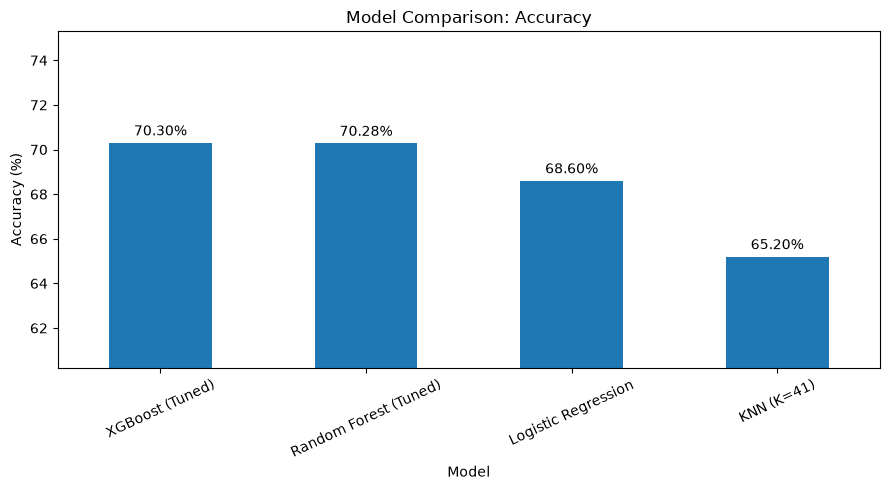

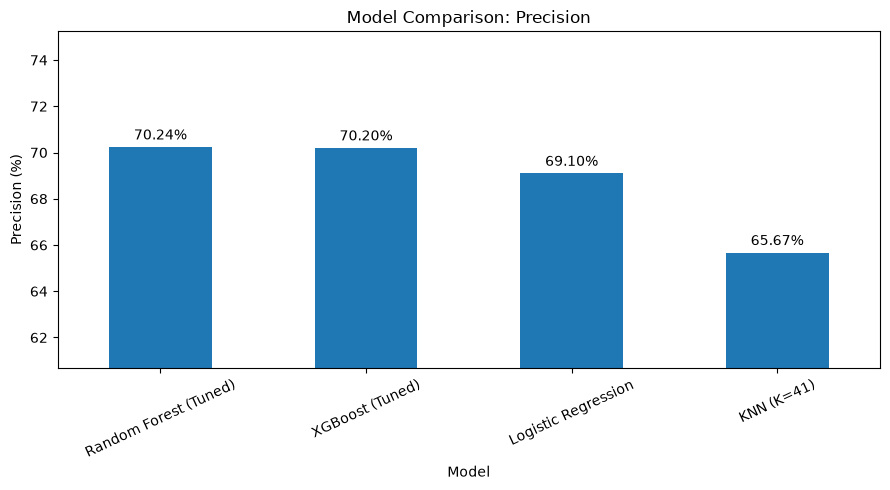

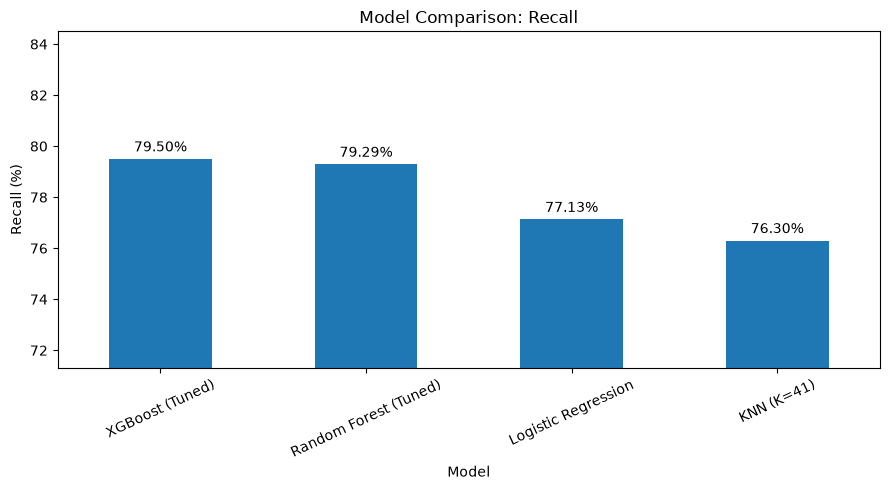

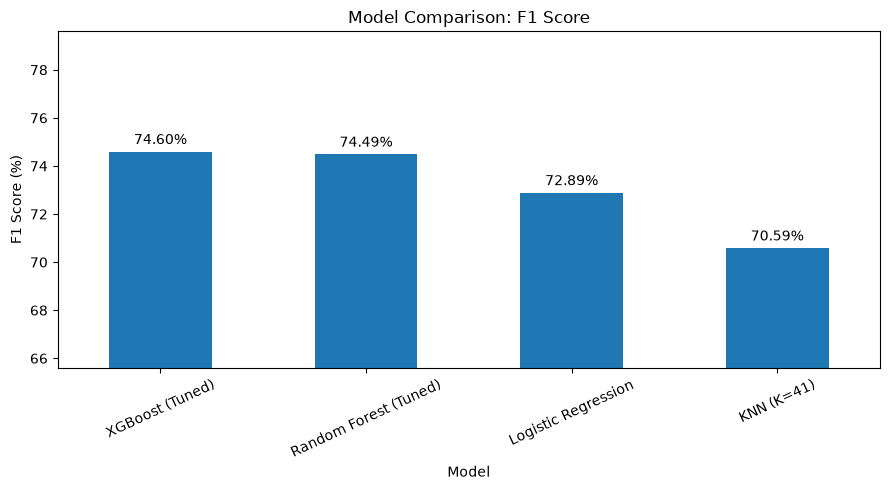

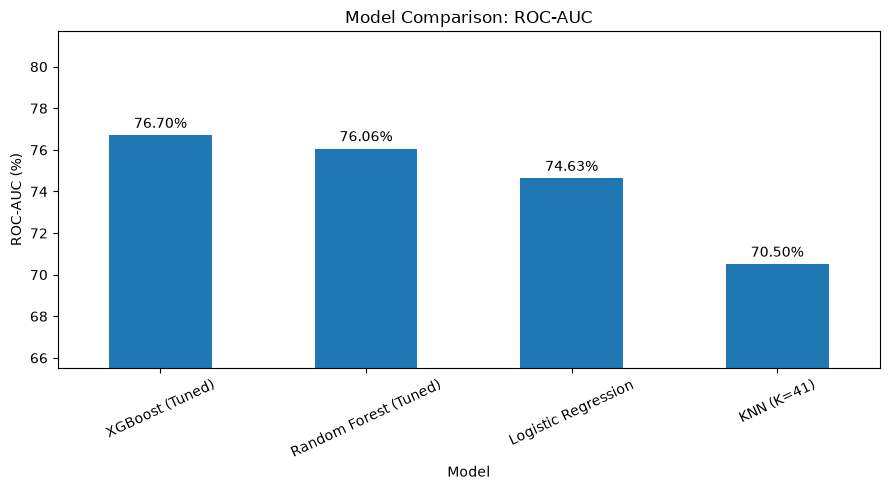

In [12]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

for metric in metrics_to_plot:
    values = results[metric] * 100

    plt.figure(figsize=(9, 5))
    ax = values.sort_values(ascending=False).plot(
        kind="bar",
        rot=25
    )

    plt.title(f"Model Comparison: {metric}")
    plt.ylabel(f"{metric} (%)")

    # Zoom in to highlight differences between models
    plt.ylim(
        max(0, values.min() - 5),
        min(100, values.max() + 5)
    )

    # Display the exact percentage above each bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)

    plt.xlabel("Model")
    plt.tight_layout()
    plt.show()

## 4. Confusion Matrix Comparison

Confusion matrices show the types of prediction errors each model makes.

- True negatives (TN): failed campaigns correctly predicted as failed.
- False positives (FP): failed campaigns incorrectly predicted as successful.
- False negatives (FN): successful campaigns incorrectly predicted as failed.
- True positives (TP): successful campaigns correctly predicted as successful.

The matrices use actual outcomes as rows and predicted outcomes as columns.

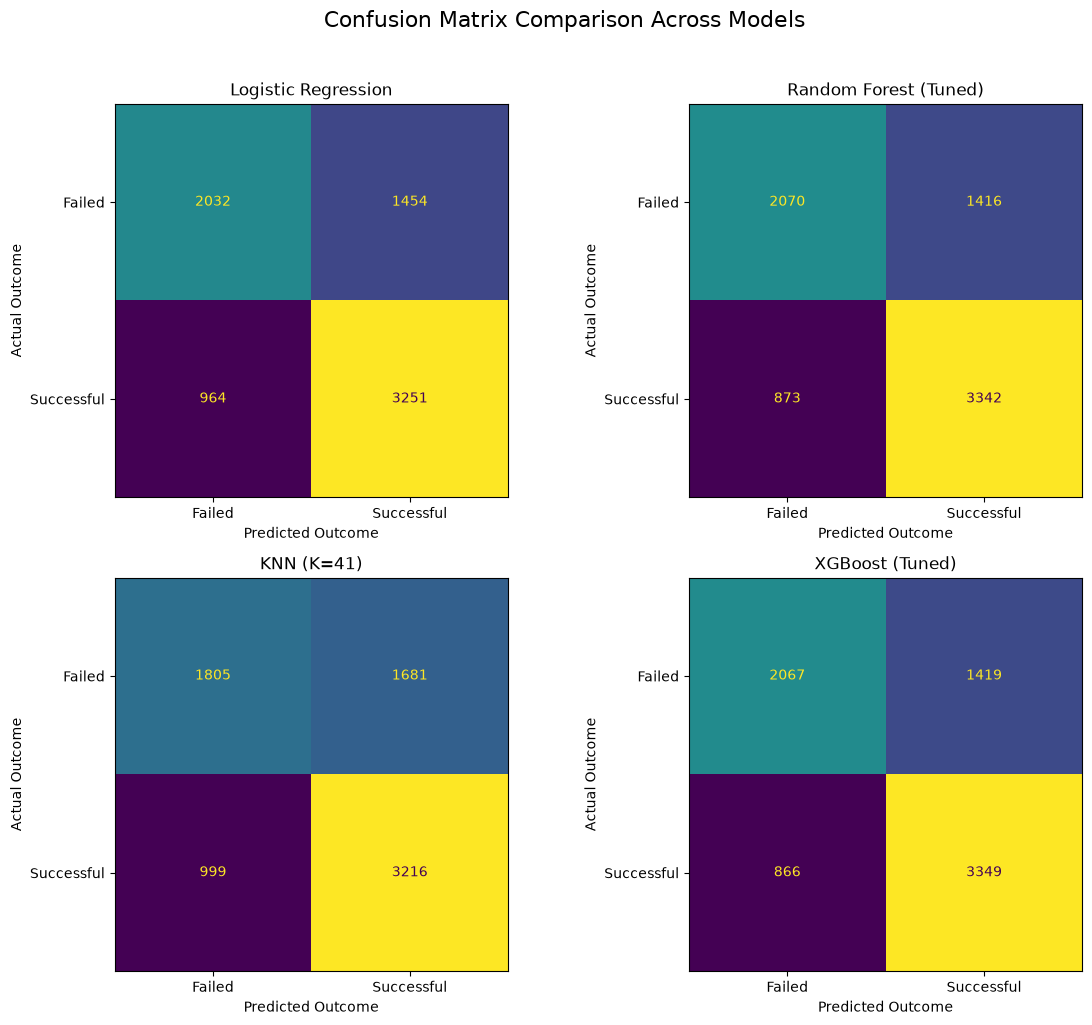

In [13]:
confusion_matrices = {
    "Logistic Regression": np.array([
        [2032, 1454],
        [964, 3251]
    ]),
    "Random Forest (Tuned)": np.array([
        [2070, 1416],
        [873, 3342]
    ]),
    "KNN (K=41)": confusion_matrix(y_test, knn_predictions),
    "XGBoost (Tuned)": np.array([
        [2067, 1419],
        [866, 3349]
    ])
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, matrix) in zip(
    axes.flatten(),
    confusion_matrices.items()
):
    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Failed", "Successful"]
    )

    display.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

fig.suptitle(
    "Confusion Matrix Comparison Across Models",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

### Final Model Selection

Based on the comparison, tuned XGBoost is the preferred model for the Kickstarter recommendation engine. It achieves the highest reported accuracy (70.30%), recall (79.50%), F1 score (74.60%), and ROC-AUC (76.70%). These results indicate that XGBoost performs slightly better overall and identifies a greater proportion of successful campaigns than the other evaluated models.

Random Forest is a close alternative, with comparable performance and slightly higher precision (70.24% compared with XGBoost's 70.20%). The difference between these models is small, so the choice should also consider the consequences of false-positive and false-negative predictions. Further validation would help determine whether XGBoost's small performance advantage generalizes to unseen campaigns.

## 6. Conclusion

The comparison suggests that the tuned tree-based models outperform Logistic Regression and KNN on the reported test metrics. XGBoost is the preliminary preferred model because it has the strongest reported ROC-AUC, recall, and F1 score, although Random Forest performs very similarly.

For Kickstarter campaign recommendations, these models could help users identify campaigns with characteristics associated with success. However, the models are not perfectly accurate and should support, rather than replace, a user's judgment.

The analysis is limited to the selected pre-launch features, including campaign goal, duration, number of reward levels, category, subcategory, and state. Campaign success also depends on factors not represented in these features. Further evaluation, probability calibration, and a review of false-positive and false-negative costs would be useful before deploying the model.